# 02 — Run full validation detection

Five intensity features: Histogram, Entropy, Entropy×Contrast, Normalized Contrast, Spatial Entropy Difference. All 120 validation images including negatives. This notebook contains the detector code itself: **no sibling Python files are required**. Default loads embedded saved results; change RUN_AGAIN=True to recompute.

12 windows, half strides, 32-bin histograms, independent Vistas role=template class-average references, NMS IoU .3, top1000 before NMS and max100 outputs/class. Evaluation: same-class one-to-one IoU>=.5. Thresholds are selected on validation, so results are development scores, not final held-out estimates. Original source annotation errors/duplicates are retained; one invalid box is excluded. Entropy here uses 32 bins, while notebook 01 crop exploration uses 256 gray levels.


**Colab:** before accessing images or rerunning detection, run:
```python
from google.colab import drive
drive.mount('/content/drive')
```
The known Drive path is prefilled. Only `Test Dataset/validation/` and `vistas_templates/` are needed. Keep their original CSVs/subfolders. Test is not needed. Dependencies: numpy, pandas, pillow, matplotlib; ipywidgets only for the optional explorer. Saved summary tables work without mounting Drive.


In [1]:
from pathlib import Path
import json,io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.patches import Rectangle
from IPython.display import display

# Colab: mount Drive when images/templates are needed.
COLAB_PROJECT=Path('/content/drive/MyDrive/ComputerVision/Midterm/midterm-csc74030-main')
PROJECT=COLAB_PROJECT
if not PROJECT.is_dir():
    PROJECT=next((p for p in [Path.cwd(),*Path.cwd().parents]
                  if (p/'Test Dataset/validation/images.csv').is_file()),COLAB_PROJECT)
# Change PROJECT above if your dataset is elsewhere.


## Detector functions — Histogram and Entropy

In [2]:
"""Validation-only multi-scale intensity detector; no test access or fitting on NYC GT."""
from pathlib import Path
from time import perf_counter
import argparse, csv, json
from collections import Counter
import numpy as np
from PIL import Image
CLASSES = ('cone', 'sign')
GEOMETRIES = tuple(((s, s * r) for s in (8, 16, 24, 32, 48, 64) for r in (1, 2)))

def read_csv(p):
    with p.open(newline='', encoding='utf-8-sig') as f:
        return list(csv.DictReader(f))

def write_csv(p, rows):
    if not rows:
        return
    with p.open('w', newline='') as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0]))
        w.writeheader()
        w.writerows(rows)

def positions(length, window, stride):
    if window > length:
        return np.empty(0, dtype=int)
    return np.unique(np.r_[np.arange(0, length - window + 1, stride), length - window])

def make_windows(w, h, fraction=0.5):
    all_boxes = []
    for bw, bh in GEOMETRIES:
        xs = positions(w, bw, max(1, round(bw * fraction)))
        ys = positions(h, bh, max(1, round(bh * fraction)))
        xx, yy = np.meshgrid(xs, ys)
        x, y = (xx.ravel(), yy.ravel())
        all_boxes.append(np.column_stack([x, y, x + bw, y + bh]))
    return np.concatenate(all_boxes).astype(np.int32)

def histograms(gray, boxes, bins=32):
    """Exact quantized counts via one integral image at a time; bounded memory."""
    quantized = (gray.astype(np.uint16) * bins // 256).astype(np.uint8)
    x0, y0, x1, y1 = boxes.T
    features = np.empty((len(boxes), bins), dtype=np.float32)
    area = (x1 - x0) * (y1 - y0)
    for b in range(bins):
        integral = np.pad((quantized == b).astype(np.int32), ((1, 0), (1, 0))).cumsum(0, dtype=np.int32).cumsum(1, dtype=np.int32)
        features[:, b] = (integral[y1, x1] - integral[y0, x1] - integral[y1, x0] + integral[y0, x0]) / area
    return features

def entropy(hist):
    return -(hist * np.log2(np.maximum(hist, 1e-30))).sum(axis=-1)

def build_templates(root, bins):
    features = {c: [] for c in CLASSES}
    for row in read_csv(root / 'templates.csv'):
        if row['role'] != 'template' or row['class'] not in CLASSES:
            continue
        with Image.open(root / row['crop']) as im:
            gray = np.array(im.convert('L'))
        with Image.open(root / row['mask']) as im:
            mask = np.array(im.convert('L')) > 0
        if mask.shape != gray.shape or not mask.any():
            raise ValueError(f'Invalid mask {row}')
        counts = np.bincount(gray[mask].astype(np.uint16) * bins // 256, minlength=bins)
        features[row['class']].append(counts / counts.sum())
    model = {}
    for c, rows in features.items():
        if not rows:
            raise ValueError('No template rows for ' + c)
        data = np.array(rows)
        model[c] = {'count': len(rows), 'histogram': data.mean(0).tolist(), 'entropy': float(entropy(data).mean())}
    return model

def distances(features, model, feature):
    if feature == 'histogram':
        target = np.array(model['histogram'], dtype=np.float32)
        return ((features - target) ** 2 / np.maximum(np.maximum(features, target), 1e-30)).sum(1)
    if feature == 'entropy':
        return np.abs(entropy(features) - model['entropy'])
    raise ValueError(feature)

def ious(box, others):
    lt = np.maximum(box[:2], others[:, :2])
    rb = np.minimum(box[2:], others[:, 2:])
    wh = np.maximum(rb - lt, 0)
    inter = wh[:, 0] * wh[:, 1]
    area = (box[2] - box[0]) * (box[3] - box[1])
    areas = (others[:, 2] - others[:, 0]) * (others[:, 3] - others[:, 1])
    return inter / np.maximum(area + areas - inter, 1e-30)

def nms(boxes, distance, overlap=0.3, pre_top=1000, max_detections=100):
    order = np.lexsort((np.arange(len(distance)), distance))[:pre_top]
    kept = []
    while len(order) and len(kept) < max_detections:
        i = order[0]
        kept.append(i)
        rest = order[1:]
        order = rest[ious(boxes[i], boxes[rest]) <= overlap]
    return np.array(kept, dtype=int)

def match_detections(pred, gt, threshold=0.5):
    """Predictions sorted by ascending distance; class supplied by caller."""
    used = set()
    tp = 0
    for det in sorted(pred, key=lambda d: (d['distance'], d['box'])):
        overlap = ious(np.array(det['box']), np.array(gt).reshape(-1, 4))
        options = [i for i, v in enumerate(overlap) if i not in used and v >= threshold]
        if options:
            best = max(options, key=lambda i: overlap[i])
            used.add(best)
            tp += 1
    return (tp, len(pred) - tp, len(gt) - tp)

def metrics(tp, fp, fn):
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    return dict(tp=int(tp), fp=int(fp), fn=int(fn), precision=p, recall=r, f1=2 * p * r / (p + r) if p + r else 0.0)

def evaluate(records, predictions, ground_truth, thresholds, feature, group=None, cls=None):
    counts = np.zeros(3, dtype=int)
    for image in records:
        if group is not None and image['group'] != group:
            continue
        for c in [cls] if cls else CLASSES:
            ds = [d for d in predictions[image['image']][feature][c] if d['distance'] <= thresholds[c]]
            counts += match_detections(ds, ground_truth.get((image['image'], c), []))
    return metrics(*counts)

def run(project, output, fraction=0.5):
    output.mkdir(parents=True, exist_ok=True)
    data = project / 'Test Dataset' / 'validation'
    images = read_csv(data / 'images.csv')
    meta = {r['image']: r for r in images}
    gt = {}
    invalid = []
    for idx, r in enumerate(read_csv(data / 'annotations.csv')):
        box = [float(r[k]) for k in ('x0', 'y0', 'x1', 'y1')]
        im = meta[r['image']]
        if not (0 <= box[0] < box[2] <= int(im['width']) and 0 <= box[1] < box[3] <= int(im['height'])):
            invalid.append(dict(r, annotation_row=idx))
            continue
        if r['class'] in CLASSES:
            gt.setdefault((r['image'], r['class']), []).append(box)
    write_csv(output / 'invalid_annotations.csv', invalid)
    start = perf_counter()
    model = build_templates(project / 'vistas_templates', 32)
    template_time = perf_counter() - start
    predictions = {}
    timings = []
    for index, image in enumerate(images):
        start = perf_counter()
        with Image.open(data / image['image']) as im:
            gray = np.array(im.convert('L'))
        boxes = make_windows(gray.shape[1], gray.shape[0], fraction)
        features = histograms(gray, boxes)
        extraction_time = perf_counter() - start
        predictions[image['image']] = {}
        row = dict(image=image['image'], group=image['group'], windows=len(boxes), shared_extraction_seconds=extraction_time)
        for feature in ('histogram', 'entropy'):
            start = perf_counter()
            result = {}
            for c in CLASSES:
                d = distances(features, model[c], feature)
                kept = nms(boxes, d)
                result[c] = [dict(box=boxes[i].tolist(), distance=float(d[i])) for i in kept]
            predictions[image['image']][feature] = result
            row[feature + '_matching_nms_seconds'] = perf_counter() - start
        timings.append(row)
        print(f"{index + 1}/{len(images)} {image['image']}: {len(boxes)} windows", flush=True)
    curves = []
    selected = {}
    rows = []
    for feature, grid in [('histogram', np.linspace(0, 2, 41)), ('entropy', np.linspace(0, 5, 51))]:
        selected[feature] = {}
        for c in CLASSES:
            class_curves = []
            for t in grid:
                score = evaluate(images, predictions, gt, {k: float(t) for k in CLASSES}, feature, cls=c)
                item = dict(feature=feature, cls=c, threshold=float(t), **score)
                curves.append(item)
                class_curves.append(item)
            best = max(class_curves, key=lambda x: (x['f1'], x['precision'], -x['threshold']))
            selected[feature][c] = best['threshold']
        for group in [None, 'cone_only', 'sign_only', 'both', 'negative']:
            rows.append(dict(feature=feature, scope=group or 'all', **evaluate(images, predictions, gt, selected[feature], feature, group=group)))
        for c in CLASSES:
            rows.append(dict(feature=feature, scope=c, **evaluate(images, predictions, gt, selected[feature], feature, cls=c)))
    write_csv(output / 'threshold_curves.csv', curves)
    write_csv(output / 'metrics.csv', rows)
    write_csv(output / 'timings.csv', timings)
    (output / 'predictions.json').write_text(json.dumps(predictions))
    summary = dict(images=len(images), valid_gt=sum(map(len, gt.values())), invalid_gt=len(invalid), image_groups=dict(Counter((i['group'] for i in images))), bins=32, geometries=GEOMETRIES, stride_fraction=fraction, nms_iou=0.3, pre_nms_top_k_per_class=1000, max_detections_per_class=100, evaluation_iou=0.5, selected_thresholds=selected, templates=model, template_setup_seconds=template_time, source=str(data), note='Validation-tuned development results; original uncorrected source boxes retained, including duplicates. No test access. Mask-only template averages compared with full-window features.', speed={})
    for feature in ('histogram', 'entropy'):
        shared = sum((r['shared_extraction_seconds'] for r in timings))
        matching = sum((r[feature + '_matching_nms_seconds'] for r in timings))
        summary['speed'][feature] = dict(total_seconds=shared + matching, seconds_per_image=(shared + matching) / len(images), fps=len(images) / (shared + matching), shared_extraction_seconds=shared, matching_nms_seconds=matching)
    (output / 'summary.json').write_text(json.dumps(summary, indent=2))
    print(json.dumps(dict(metrics=rows, speed=summary['speed'], thresholds=selected), indent=2))
    return summary
run_baseline=run

## Additional feature functions

In [3]:
"""Controlled feature-engineering extension of the existing average-template baseline."""
from pathlib import Path
from time import perf_counter
from collections import Counter
import argparse, sys, json
import numpy as np
from PIL import Image
FEATURES = ('entropy_contrast', 'normalized_contrast', 'spatial_entropy_difference')

def from_pixels(gray, mask=None, bins=32):
    if mask is None:
        mask = np.ones(gray.shape, dtype=bool)
    pixels = gray[mask].astype(float)

    def h(values):
        if not len(values):
            return 0.0
        count = np.bincount(values.astype(np.uint16) * bins // 256, minlength=bins)
        return float(entropy(count / count.sum()))
    mu = pixels.mean()
    sd = pixels.std()
    mid = gray.shape[0] // 2
    spatial = abs(h(gray[:mid][mask[:mid]]) - h(gray[mid:][mask[mid:]])) if mid else 0.0
    return np.array([h(pixels) * sd, sd / (mu + 1), spatial])

def features_for_windows(gray, boxes):
    top = boxes.copy()
    bottom = boxes.copy()
    middle = (boxes[:, 1] + boxes[:, 3]) // 2
    top[:, 3] = middle
    bottom[:, 1] = middle
    hist = histograms(gray, np.concatenate([boxes, top, bottom]))
    n = len(boxes)
    h = entropy(hist[:n])
    delta = np.abs(entropy(hist[n:2 * n]) - entropy(hist[2 * n:]))
    x0, y0, x1, y1 = boxes.T
    area = (x1 - x0) * (y1 - y0)
    moments = []
    for power in (1, 2):
        values = gray.astype(np.float64) ** power
        integral = np.pad(values, ((1, 0), (1, 0))).cumsum(0).cumsum(1)
        moments.append((integral[y1, x1] - integral[y0, x1] - integral[y1, x0] + integral[y0, x0]) / area)
    mu = moments[0]
    sd = np.sqrt(np.maximum(moments[1] - mu * mu, 0))
    return np.column_stack([h * sd, sd / (mu + 1), delta])

def templates(project):
    records = {c: [] for c in ['cone', 'sign']}
    for row in read_csv(project / 'vistas_templates/templates.csv'):
        if row['role'] != 'template':
            continue
        with Image.open(project / 'vistas_templates' / row['crop']) as im:
            gray = np.array(im.convert('L'))
        with Image.open(project / 'vistas_templates' / row['mask']) as im:
            mask = np.array(im.convert('L')) > 0
        records[row['class']].append(from_pixels(gray, mask))
    return {c: np.array(values).mean(0).tolist() for c, values in records.items()}

def main(project, output):
    output.mkdir(parents=True, exist_ok=True)
    images = read_csv(project / 'Test Dataset/validation/images.csv')
    meta = {i['image']: i for i in images}
    gt = {}
    invalid = []
    for index, r in enumerate(read_csv(project / 'Test Dataset/validation/annotations.csv')):
        b = [float(r[k]) for k in ['x0', 'y0', 'x1', 'y1']]
        im = meta[r['image']]
        if not (0 <= b[0] < b[2] <= int(im['width']) and 0 <= b[1] < b[3] <= int(im['height'])):
            invalid.append(dict(r, annotation_row=index))
            continue
        gt.setdefault((r['image'], r['class']), []).append(b)
    references = templates(project)
    predictions = {}
    timings = []
    for idx, image in enumerate(images):
        start = perf_counter()
        with Image.open(project / 'Test Dataset/validation' / image['image']) as im:
            gray = np.array(im.convert('L'))
        boxes = make_windows(gray.shape[1], gray.shape[0], 0.5)
        f = features_for_windows(gray, boxes)
        shared = perf_counter() - start
        predictions[image['image']] = {}
        row = dict(image=image['image'], group=image['group'], windows=len(boxes), shared_extraction_seconds=shared)
        for k, feature in enumerate(FEATURES):
            start = perf_counter()
            predictions[image['image']][feature] = {}
            for c in ['cone', 'sign']:
                d = np.abs(f[:, k] - references[c][k])
                keep = nms(boxes, d)
                predictions[image['image']][feature][c] = [dict(box=boxes[i].tolist(), distance=float(d[i])) for i in keep]
            row[feature + '_matching_nms_seconds'] = perf_counter() - start
        timings.append(row)
        print(idx + 1, '/', len(images), flush=True)
    curves = []
    selected = {}
    metrics = []
    for feature in FEATURES:
        selected[feature] = {}
        for c in ['cone', 'sign']:
            ds = np.array([d['distance'] for im in predictions.values() for d in im[feature][c]])
            grid = np.unique(np.r_[0, np.quantile(ds, np.linspace(0, 1, 41))])
            items = []
            for t in grid:
                score = evaluate(images, predictions, gt, dict(cone=float(t), sign=float(t)), feature, cls=c)
                item = dict(feature=feature, cls=c, threshold=float(t), **score)
                items.append(item)
                curves.append(item)
            best = max(items, key=lambda r: (r['f1'], r['precision'], -r['threshold']))
            selected[feature][c] = best['threshold']
        for group in [None, 'cone_only', 'sign_only', 'both', 'negative']:
            metrics.append(dict(feature=feature, scope=group or 'all', **evaluate(images, predictions, gt, selected[feature], feature, group=group)))
        for c in ['cone', 'sign']:
            metrics.append(dict(feature=feature, scope=c, **evaluate(images, predictions, gt, selected[feature], feature, cls=c)))
    write_csv(output / 'metrics.csv', metrics)
    write_csv(output / 'threshold_curves.csv', curves)
    write_csv(output / 'timings.csv', timings)
    write_csv(output / 'invalid_annotations.csv', invalid)
    (output / 'predictions.json').write_text(json.dumps(predictions))
    speed = {}
    for feature in FEATURES:
        seconds = sum((r['shared_extraction_seconds'] + r[feature + '_matching_nms_seconds'] for r in timings))
        speed[feature] = dict(total_seconds=seconds, seconds_per_image=seconds / len(images))
    summary = dict(images=len(images), valid_gt=sum(map(len, gt.values())), invalid_gt=len(invalid), templates=references, selected_thresholds=selected, bins=32, epsilon=1, stride_fraction=0.5, nms_iou=0.3, pre_nms_top_k_per_class=1000, max_detections_per_class=100, evaluation_iou=0.5, speed=speed, note='Exploratory validation-tuned results; same average-mask-template/candidate/NMS protocol as baseline, scale-specific quantile threshold grids. Shared extraction computes all three engineered features; not individually optimized timing.')
    (output / 'summary.json').write_text(json.dumps(summary, indent=2))
    print(json.dumps(metrics, indent=2))
run_engineered=main

## Saved results snapshot

This collapsed cell contains compressed saved results for all validation images.

In [4]:
# Embedded saved experiment results; no external result files are required.
import base64,zlib,json,io
_SAVED=json.loads(zlib.decompress(base64.b64decode('...')))
def saved_json(key):return json.loads(_SAVED[key])
def saved_csv(key):return pd.read_csv(io.StringIO(_SAVED[key]))


In [5]:
RUN_AGAIN=False
# New output files go outside this notebook-only folder.
OUTPUT=PROJECT/'intensity_results/full_validation'
if RUN_AGAIN:
    run_baseline(PROJECT,OUTPUT/'baseline',fraction=.5)
    run_engineered(PROJECT,OUTPUT/'engineered')
    def result_json(label,name):return json.loads((OUTPUT/label/name).read_text())
    def result_csv(label,name):return pd.read_csv(OUTPUT/label/name)
else:
    def result_json(label,name):return saved_json(label+'/'+name)
    def result_csv(label,name):return saved_csv(label+'/'+name)
metrics=pd.concat([result_csv(label,'metrics.csv') for label in ['baseline','engineered']],ignore_index=True)
print('120 validation images; 228 valid source boxes; test untouched.')
display(metrics.round(6))


120 validation images; 228 valid source boxes; test untouched.


,feature,scope,tp,fp,fn,precision,recall,f1
0,histogram,all,5,19631,223,0.000255,0.021930,0.000503
1,histogram,cone_only,1,6581,77,0.000152,0.012821,0.000300
2,histogram,sign_only,2,6994,54,0.000286,0.035714,0.000567
3,histogram,both,2,2776,92,0.000720,0.021277,0.001393
4,histogram,negative,0,3280,0,0.000000,0.000000,0.000000
5,histogram,cone,2,10819,150,0.000185,0.013158,0.000365
6,histogram,sign,3,8812,73,0.000340,0.039474,0.000675
7,entropy,all,0,2,228,0.000000,0.000000,0.000000
8,entropy,cone_only,0,0,78,0.000000,0.000000,0.000000
9,entropy,sign_only,0,1,56,0.000000,0.000000,0.000000


## Overall results, false positives and speed

Timing includes shared extraction and matching/NMS, not threshold sweeps or metrics. The engineered run computes three features together, so timing is not independently optimized per feature. See detector configuration for limits.

,feature,scope,tp,fp,fn,precision,recall,f1
0,histogram,all,5,19631,223,0.000255,0.021930,0.000503
7,entropy,all,0,2,228,0.000000,0.000000,0.000000
14,entropy_contrast,all,0,0,228,0.000000,0.000000,0.000000
21,normalized_contrast,all,2,4798,226,0.000417,0.008772,0.000796
28,spatial_entropy_difference,all,1,5100,227,0.000196,0.004386,0.000375


,feature,fp
4,histogram,3280
11,entropy,0
18,entropy_contrast,0
25,normalized_contrast,702
32,spatial_entropy_difference,874


,total_seconds,seconds_per_image,fps,shared_extraction_seconds,matching_nms_seconds
histogram,18.2619,0.1522,6.5711,15.8234,2.4385
entropy,18.8516,0.1571,6.3655,15.8234,3.0283
entropy_contrast,34.4834,0.2874,NaN,NaN,NaN
normalized_contrast,34.5268,0.2877,NaN,NaN,NaN
spatial_entropy_difference,34.5090,0.2876,NaN,NaN,NaN


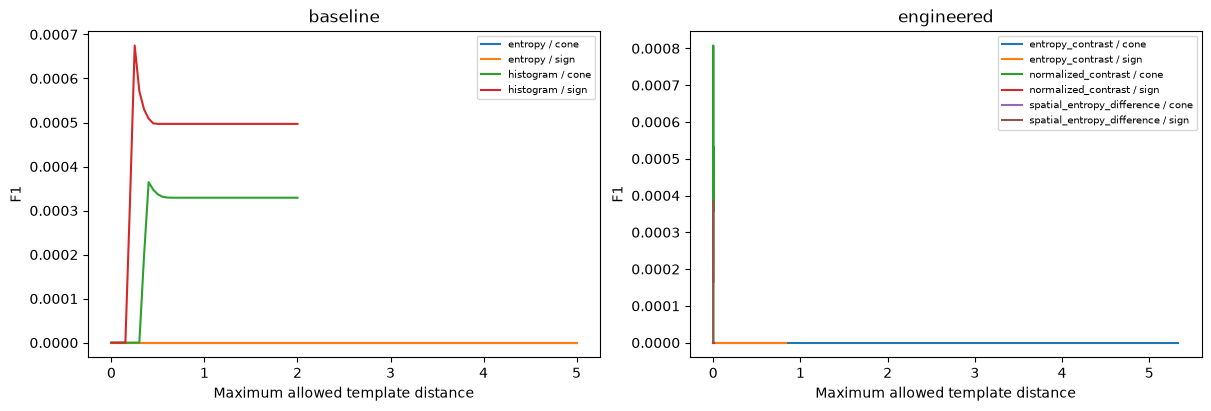

In [6]:
display(metrics[metrics.scope=='all'].round(6))
display(metrics[metrics.scope=='negative'][['feature','fp']])
speed={}
for label in ['baseline','engineered']:speed.update(result_json(label,'summary.json')['speed'])
display(pd.DataFrame(speed).T.round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for ax,label in zip(axes,['baseline','engineered']):
    curves=result_csv(label,'threshold_curves.csv')
    for (feature,cls),rows in curves.groupby(['feature','cls']):
        ax.plot(rows.threshold,rows.f1,label=feature+' / '+cls)
    ax.set(xlabel='Maximum allowed template distance',ylabel='F1',title=label);ax.legend(fontsize=7)
plt.show()


## Optional grayscale detection display

Set SHOW_IMAGE=True after mounting Drive. Green dashed boxes are source annotations; red boxes are retained predictions. The display limit does not affect metrics.

In [7]:
SHOW_IMAGE=False
IMAGE_INDEX=0
FEATURE='histogram'
if SHOW_IMAGE:
    label='baseline' if FEATURE in ['histogram','entropy'] else 'engineered'
    config=result_json(label,'summary.json')
    preds=result_json(label,'predictions.json')
    data=PROJECT/'Test Dataset/validation'
    images=pd.read_csv(data/'images.csv');gt=pd.read_csv(data/'annotations.csv');row=images.iloc[IMAGE_INDEX]
    with Image.open(data/row['image']) as im:gray=np.array(im.convert('L'))
    fig,ax=plt.subplots(figsize=(14,9));ax.imshow(gray,cmap='gray',vmin=0,vmax=255)
    for _,b in gt[gt.image==row['image']].iterrows():
        if b.x1>b.x0 and b.y1>b.y0:ax.add_patch(Rectangle((b.x0,b.y0),b.x1-b.x0,b.y1-b.y0,fill=False,edgecolor='lime',linestyle='--'))
    retained=[]
    for cls in ['cone','sign']:
        retained.extend(dict(d,cls=cls) for d in preds[row['image']][FEATURE][cls] if d['distance']<=config['selected_thresholds'][FEATURE][cls])
    for d in sorted(retained,key=lambda d:d['distance'])[:20]:
        x0,y0,x1,y1=d['box'];ax.add_patch(Rectangle((x0,y0),x1-x0,y1-y0,fill=False,edgecolor='red'))
        ax.text(x0,y0,d['cls'],color='red',fontsize=8)
    ax.set_title(f'{FEATURE}: {len(retained)} outputs; up to 20 shown');ax.axis('off');plt.show()


## Interpretation

None of the current average-template intensity configurations is a useful full-image detector. Crop separation is not localization accuracy. Mask-only template statistics differ from background-containing candidate windows. Candidate ranking/caps are diagnosed in notebook 04. Threshold grids for the engineered scalar features are scale-specific quantiles; baseline grids are fixed numeric values, so tiny F1 differences are not definitive feature advantages. Test remains untouched.
